# Л2 — Сегментація й пошук закономірностей

Коли дані зібрано й очищено, з них починають видобувати знання. Універсального порядку тут немає: метод обирають під питання, на яке шукають відповідь.

Ноутбук нижче показує кілька поширених методів на одних даних і пастки, через які висновок буває хибним. Він не охоплює всіх методів (є, наприклад, DBSCAN чи змішані гаусові моделі), а приклади в ньому часом спрощені. Проте він дасть розуміння, що кожен метод показує і як його прочитати. Більше туторіалів — у [Kaggle Learn](https://www.kaggle.com/learn), зокрема [Feature Engineering](https://www.kaggle.com/learn/feature-engineering) з уроками про k-середні й головні компоненти.

| Питання | Метод | Кроки |
|---|---|---|
| На які групи діляться абоненти? | кластеризація: k-середні, метод Варда | 2, 4–7 |
| Які показники змінюються разом? | головні компоненти (PCA) | 3 |
| Як наочно показати, хто на кого схожий? | карта Кохонена | 8 |
| Які події трапляються разом? | асоціативні правила | 9 |
| Чи не обманює простий висновок? | перевірка пасток | 10 |

Спільні правила для всіх методів:

- методам на відстанях (k-середні, Вард, Кохонен) потрібен однаковий масштаб ознак, інакше ознака з великими числами переважить решту;
- кількість кластерів обирають і за метриками, і за тим, чи можна кластер пояснити;
- результат одного методу варто перевірити іншим;
- зв'язок у даних ще не означає причину: його може створювати третій чинник, а в частині даних він може бути протилежним.

Шаблон веде покроково: у кожному кроці — навіщо він і що зробити, у клітинці з `TODO` — ваш код. Опис даних і таблиця пасток — у `README.md`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from minisom import MiniSom
from mlxtend.frequent_patterns import apriori, association_rules

## 1. Завантаження даних

Дані цієї роботи вже чисті, тож досить переконатися, що файли прочиталися правильно, і подивитися, що всередині. Можуть допомогти `df.head()`, `df.shape` і `df.dtypes`.

In [5]:
# TODO: завантажте customers.parquet і events.csv свого варіанта з папки variants/<варіант>/
# customers = pd.read_parquet(...)
# events = pd.read_csv(..., parse_dates=["event_ts"])

customers = pd.read_parquet("customers.parquet")
events = pd.read_csv("events.csv", parse_dates=["event_ts"])

print("customers:", customers.shape)
print("events:", events.shape)

print("head customers: ")
display(customers.head())

print("head events: ")
display(events.head())

print("type customers: ")
print(customers.dtypes)

print("type events: ")
print(events.dtypes)

customers: (2000, 15)
events: (4079, 3)
head customers: 


,abonent_id,avg_daily_kwh,night_share,seasonality,weekend_ratio,stability,annual_charge_uah,avg_price_uah_kwh,voltage_dev_mean,loss_index_mean,tariff,meter_type,district,connection_year,churned
0,AB10001,19.242,0.3621,1.6752,0.9320,0.6877,24847.78,3.538,2.5756,5.0420,dual_zone,IND_1985,south,2009,0
1,AB10002,24.980,0.1233,1.2283,0.8598,0.7654,62456.93,6.850,5.5486,6.8498,business,SMART_B,west,1994,1
2,AB10003,8.115,0.1888,1.5943,1.0462,0.7135,11587.32,3.912,4.1090,9.7036,dual_zone,SMART_A,south,2020,0
3,AB10004,10.477,0.1154,1.0614,0.7261,0.8104,16519.68,4.320,5.5457,14.1345,single,IND_1985,north,1993,1
4,AB10005,23.444,0.1237,1.2613,0.6873,0.7615,58616.14,6.850,7.6942,24.4307,business,IND_1985,west,1980,0


head events: 


,abonent_id,event_ts,event_type
0,AB10002,2025-09-06 16:00:00,complaint
1,AB10002,2025-09-24 15:00:00,payment_delay
2,AB10002,2025-10-21 17:00:00,tariff_change
3,AB10002,2025-11-02 00:00:00,churn
4,AB10003,2025-12-20 00:00:00,complaint


type customers: 
abonent_id               str
avg_daily_kwh        float64
night_share          float64
seasonality          float64
weekend_ratio        float64
stability            float64
annual_charge_uah    float64
avg_price_uah_kwh    float64
voltage_dev_mean     float64
loss_index_mean      float64
tariff                   str
meter_type               str
district                 str
connection_year        int64
churned                int64
dtype: object
type events: 
abonent_id               str
event_ts      datetime64[us]
event_type               str
dtype: object


## 2. Ознаки для сегментації

Кластеризація спирається на просторову близькість: кожен абонент — точка в просторі ознак, і схожі абоненти лежать поруч. Відстань рахується по всіх ознаках разом, тож ознака з великими числами переважить решту. Обсяг споживання в різних абонентів різниться в сотні разів, тому його спершу логарифмують, а потім усі ознаки стандартизують: середнє 0, стандартне відхилення 1. Грошей і договору серед ознак немає: сегмент описує, як абонент споживає.

Візьміть із `customers` колонки `features`, замініть `avg_daily_kwh` її натуральним логарифмом і стандартизуйте всі колонки. Результат назвіть `X`. Самі `customers` не змінюйте: у кроках 3 і 7 потрібні вихідні значення. Можуть допомогти `np.log` і `StandardScaler().fit_transform`.

In [7]:
features = ["avg_daily_kwh", "night_share", "seasonality", "weekend_ratio", "stability"]

# TODO: X — ознаки features з логарифмом avg_daily_kwh, стандартизован
standard_data = customers[features].copy()

standard_data["avg_daily_kwh"] = np.log(standard_data["avg_daily_kwh"])

X = StandardScaler().fit_transform(standard_data)

display(pd.DataFrame(X, columns=features).head())

,avg_daily_kwh,night_share,seasonality,weekend_ratio,stability
0,0.066286,0.745727,0.512479,-0.200678,-0.438805
1,0.426992,-1.088908,-1.046854,-0.587355,1.225009
2,-1.127012,-0.585689,0.230201,0.410936,0.113659
3,-0.773924,-1.149601,-1.629206,-1.303405,2.188608
4,0.339282,-1.085835,-0.931710,-1.511204,1.141497


## 3. Головні компоненти (PCA)

PCA повертає осі так, щоб перша головна компонента (principal component) йшла вздовж найбільшого розкиду даних, друга — вздовж найбільшого з решти, і так далі. Кожна компонента — лінійна комбінація вихідних показників. Найчастіше PCA використовують для зменшення розмірності: стиснути багато пов'язаних показників до кількох компонент перед моделлю чи для графіка. Але за нею можна й побачити, які показники змінюються разом, як у факторному аналізі. Тут саме це: погляд на 9 числових показників абонентів (усі числові колонки, крім `connection_year` і `churned`). На сегменти він не впливає.

Як читати результат:

- **eigenvalue** (власне значення) — скільки розкиду пояснює компонента в «одиницях одного показника»: сума eigenvalues ≈ кількість показників. Критерій Кайзера лишає компоненти з eigenvalue більше 1: кожна з них пояснює більше, ніж один показник;
- **loadings** (факторні навантаження) — кореляція показника з компонентою, від −1 до 1. Показники з великим за модулем loading (приблизно від 0.5) і однаковим знаком змінюються разом, з протилежним — у різні боки. Знак самої компоненти умовний: якщо перевернути всі знаки, зміст той самий;
- компоненту називають за її сильними показниками.

Приклад на інших даних — 5 показників 1000 людей. Eigenvalues перших двох компонент — 2.55 і 1.83, третьої — 0.25, тож за Кайзером лишаються дві, і разом вони пояснюють 88% розкиду.

| Показник | PC1 | PC2 |
|---|---|---|
| зріст | 0.92 | −0.12 |
| вага | 0.92 | 0.00 |
| розмір взуття | 0.92 | −0.10 |
| кроків за день | −0.11 | −0.95 |
| час бігу на 1 км | 0.10 | 0.95 |

У PC1 великі й однакові за знаком loadings мають зріст, вага й розмір взуття, решта біля нуля — це «розмір тіла». У PC2 сильні лише кроки й час бігу, і знаки в них протилежні: хто більше ходить, той швидше біжить. Це «активність», а великі значення PC2 тут означають малоактивних людей, бо знак компоненти умовний.

Збережений розкид — ще не збережена користь: для прогнозу може знадобитися саме компонента з малим eigenvalue, і перевірити це можна лише моделлю з цільовою колонкою.

1. Стандартизуйте 9 колонок без логарифма й застосуйте `PCA()`. `X` із кроку 2 не перезаписуйте, він потрібен далі.
2. Виведіть eigenvalues (`explained_variance_`), explained variance ratio кожної компоненти (`explained_variance_ratio_`) і накопичену частку.
3. Виведіть кількість компонент з eigenvalue більше 1.
4. Виведіть таблицю loadings перших двох компонент.
5. Назвіть першу компоненту за її сильними показниками одним реченням — це відповідь для питання 2 звіту.

In [22]:
# TODO: PCA на 9 числових колонках
# numeric = ...
# pca = PCA().fit(...)
# loadings = pd.DataFrame(pca.components_[:2].T * np.sqrt(pca.explained_variance_[:2]), index=numeric, columns=["PC1", "PC2"])

numeric = ["avg_daily_kwh", "night_share", "seasonality", "weekend_ratio", "stability", "annual_charge_uah", "avg_price_uah_kwh", "voltage_dev_mean", "loss_index_mean"]

Y = StandardScaler().fit_transform(customers[numeric])

pca = PCA().fit(Y)

pca_result = pd.DataFrame({"PC": [f"PC{i+1}" for i in range(len(numeric))],
                                  "Eigenvalue": pca.explained_variance_,
                                  "Variance ratio": pca.explained_variance_ratio_,
                                  "Variance ratio compound": np.cumsum(pca.explained_variance_ratio_)
                                  })

display(pca_result.round(3))

kaiser = (pca.explained_variance_ > 1).sum()

print("count of components with eigenvalue > 1:", kaiser)

print(f"Rozkyd percent: {(pca_result["Variance ratio compound"][kaiser-1] * 100).round(3)} %")

loadings = pd.DataFrame(pca.components_[:2].T * np.sqrt(pca.explained_variance_[:2]),
                        index=numeric,
                        columns=["PC1", "PC2"]
                        )

print("loadings:")
display(loadings.round(3))



,PC,Eigenvalue,Variance ratio,Variance ratio compound
0,PC1,3.707,0.412,0.412
1,PC2,1.426,0.158,0.570
2,PC3,1.289,0.143,0.713
3,PC4,0.870,0.097,0.810
4,PC5,0.624,0.069,0.879
5,PC6,0.570,0.063,0.942
6,PC7,0.349,0.039,0.981
7,PC8,0.144,0.016,0.997
8,PC9,0.025,0.003,1.000


count of components with eigenvalue > 1: 3
Rozkyd percent: 71.321 %
loadings:


,PC1,PC2
avg_daily_kwh,-0.683,-0.389
night_share,0.608,-0.060
seasonality,0.760,-0.324
weekend_ratio,0.844,-0.051
stability,-0.713,0.317
annual_charge_uah,-0.788,-0.350
avg_price_uah_kwh,-0.671,-0.025
voltage_dev_mean,0.012,0.679
loss_index_mean,-0.021,0.692


Ми маємо 3 компоненти кайзера, що відповідають за 71.321 % дисперсії. Перша компонента 41.2 %

Першу компоненту можна охарактеризувати як профіль або характер споживання електроенергії, оскільки сильними показниками в ній є середнє денне навантаження (avg_daily_kwh), нічна частка (night_share), сезонність (seasonality), частка вихідних дней (weekend_ratio), стабільність (stability), річна оплата (annual_charge_uah) та середня ціна за кіловат (avg_price_uah_kwh). 

Знаки показників в першій компоненті демонструють, що стабільність та середнє денне навантаження пов'язані з більшими витратами, в той час коли показники нічна частка, сезонність, частка вихідних дней пов'язані між собою і відповідають меншим витратам.

Прикладом першого буде постійне споживання електроенергії в квартирі, тоді як сезонне споживання відповідає умовній дачі.

## 4. Кількість кластерів

k-середні ділять абонентів на k кластерів. Центр кластера (центроїд) — середнє всіх його точок, тобто усереднений представник: за ним описують увесь кластер. Алгоритм відносить кожного абонента до найближчого центру й перераховує центри, доки абоненти не перестануть переходити між кластерами. Коли кластер вдається описати як тип абонентів, його називають сегментом.

Інерція — сума квадратів відстаней від абонентів до центрів їхніх кластерів. Вона спадає з кожним новим k, тож шукають «лікоть»: місце, де спад сповільнюється. Силует, від −1 до 1, показує, наскільки абонент ближчий до свого кластера, ніж до сусіднього. Він часто найбільший при малих k, бо грубий поділ чіткіший за детальний. Але два кластери нічого не кажуть про типи споживачів, тому k обирають від 3 до 6.

Для k від 2 до 8 побудуйте k-середні на `X`, виведіть таблицю «k, інерція (`inertia_`), силует (`silhouette_score`)» і два графіки: інерція від k і силует від k.

,k,inertia,silhouette
0,2,5430.188,0.473
1,3,4062.656,0.335
2,4,3103.003,0.369
3,5,2735.481,0.325
4,6,2516.207,0.313
5,7,2342.088,0.293
6,8,2166.664,0.232


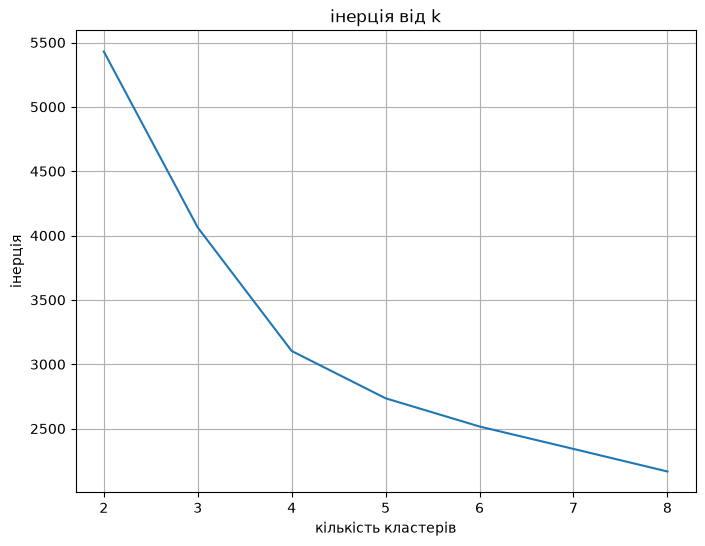

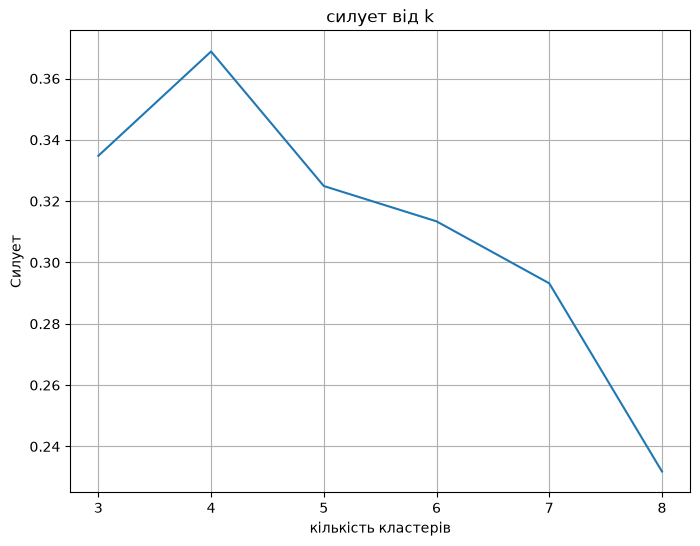

In [38]:
# TODO: таблиця й графіки для k від 2 до 8
# model = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X)

result_clusters = []

for k in range(2,9):
    model = KMeans(n_clusters=k, n_init=10).fit(X)

    inertia = model.inertia_
    silhouette = silhouette_score(X, model.labels_)

    result_clusters.append({"k": k,
                        "inertia": inertia,
                        "silhouette": silhouette
                        })

result = pd.DataFrame(result_clusters)

display(result.round(3))

plt.figure(figsize=(8,6))

plt.plot(result["k"], result["inertia"])

plt.title("інерція від k")
plt.xlabel("кількість кластерів")
plt.ylabel("інерція")
plt.grid()
plt.show()

plt.figure(figsize=(8,6))

plt.plot(result["k"][1:], result["silhouette"][1:])

plt.title("силует від k")
plt.xlabel("кількість кластерів")
plt.ylabel("Силует")
plt.grid()
plt.show()



З графіків видно, що найкраща кількість кластерів - 4. В графіку інерції, збільшення кількості кластерів після 4 набагато менше впливає на зміну інерції. В графіку силуетів, відокремивши кількість кластерів 1 та 2 бачимо, що маємо пік при кількості кластерів 4.

## 5. Ієрархічна кластеризація

Метод Варда починає з окремих абонентів і щоразу об'єднує два кластери, від злиття яких сума квадратів відстаней усередині кластерів росте найменше. Дендрограма показує всю історію об'єднань: довгі вертикальні лінії вгорі означають, що злито дуже різні кластери, і різати варто саме там.

| | k-середні | Метод Варда |
|---|---|---|
| кількість кластерів | задають наперед | не потрібна: дендрограма показує поділ на будь-яке k |
| що дає | центри кластерів; нового абонента відносять до найближчого центру | ієрархію: видно, які кластери є частинами більших |
| слабке місце | може застрягти в невдалому поділі, тому запускають кілька разів (`n_init`) | невдале раннє об'єднання не виправляється |
| великі дані | швидкий і на мільйонах рядків | рахує відстані між усіма парами, тому повільний |

Тут Вард допомагає обрати k і перевірити, чи поділ стійкий, а сегменти для `segments.csv` беруть із k-середніх: у них є центри, за якими описують сегменти й відносять нових абонентів.

1. Побудуйте `Z = linkage(X, "ward")` і дендрограму верхніх 30 об'єднань: `dendrogram(Z, truncate_mode="lastp", p=30)`.
2. Для k від 3 до 6 виведіть довжину розрізу на k кластерів. `Z[:, 2]` — висоти об'єднань, і розріз на k кластерів лежить між k-м і (k−1)-м об'єднанням з кінця.
3. Дендрограма підказує k із найбільшою довжиною розрізу: такий розріз перетинає найдовші вертикальні лінії.

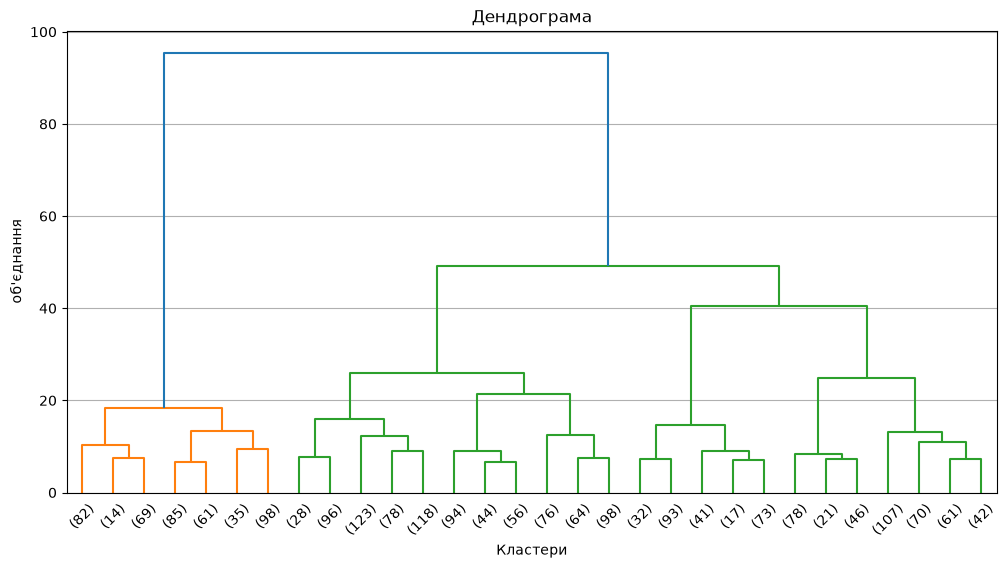

k = 3, довжина розрізу = 8.695
k = 4, довжина розрізу = 14.496
k = 5, довжина розрізу = 1.121
k = 6, довжина розрізу = 3.562


In [47]:
# TODO: дендрограма й довжини розрізів для k від 3 до 6
# cut = Z[-(k - 1), 2] - Z[-k, 2]

Z = linkage(X, "ward")

plt.figure(figsize=(12, 6))

dendrogram(Z, truncate_mode="lastp", p=30)

plt.title("Дендрограма")
plt.xlabel("Кластери")
plt.ylabel("об'єднання")

plt.grid(axis="y")
plt.show()

for k in range(3, 7): print(f"k = {k}, довжина розрізу = {(Z[-(k - 1), 2] - Z[-k, 2]):.3f}")


В результаті видно, що додавання кластерів після 4х відповідає за значено меншу суму квадратів відстаней до центру між двома кластерами. Це підтверджує результати методу k-середніх

## 6. Порівняння двох поділів

Методи будують кластери по-різному (крок 5), тож поділи можуть різнитися. Якщо вони схожі, кластери відображають структуру самих даних, а не особливість одного методу.

Як порівняти два поділи:

- **таблиця спряженості** (contingency table, `pd.crosstab`): рядок — кластер k-середніх, стовпець — кластер Варда, у клітинці — скільки абонентів потрапили в обидва. Номери в двох методах не пов'язані: кластер 0 k-середніх може відповідати кластеру 3 Варда. Тому дивляться не на діагональ, а на те, чи в кожному рядку одна велика клітинка. Якщо великих дві, цей кластер Вард ділить між двома своїми;
- **ARI** (adjusted Rand index, `adjusted_rand_score`) — одне число: наскільки однаково два поділи розкладають абонентів «разом» чи «окремо», з поправкою на випадкові збіги. Від номерів кластерів не залежить. 1 — поділи однакові, близько 0 — збігаються не більше, ніж випадкові. Орієнтовно: від 0.9 — майже однакові, 0.65–0.9 — схожі, але частина абонентів переходить, нижче 0.65 — суттєво різні.

Приклад, 2000 абонентів, три кластери, ARI 0.78:

| | Вард 1 | Вард 2 | Вард 3 |
|---|---|---|---|
| k-середні 0 | 0 | 480 | 5 |
| k-середні 1 | 610 | 10 | 0 |
| k-середні 2 | 0 | 150 | 745 |

Кластери 0 і 1 k-середніх майже цілком збігаються з кластерами Варда 2 і 1. Кластер 2 здебільшого — кластер Варда 3, але 150 його абонентів Вард відніс до кластера 2: межу між цими двома кластерами методи проводять по-різному.

1. Оберіть k від 3 до 6, зважаючи на кроки 4 і 5. Якщо вони підказують різне, вибір за вами: у звіті напишіть, на що спиралися. Якщо в кроці 7 якийсь сегмент не вдасться описати одним реченням, можна повернутися й узяти інше k.
2. Побудуйте k-середні на `X` з тими самими параметрами, що в кроці 4, і назвіть мітки кластерів `labels`: це сегменти для `segments.csv`.
3. Розріжте дендрограму на k кластерів: `fcluster(Z, k, "maxclust")`, кластери нумеруються з 1.
4. Виведіть таблицю спряженості двох поділів і ARI.
5. Знайдіть кластери, які методи ділять по-різному, або переконайтеся, що поділи майже однакові, — це відповідь для питання 2 звіту.

In [57]:
k = 4  # TODO: ваш вибір від 3 до 6

# TODO: labels k-середніх, кластери Варда, таблиця спряженості й ARI

labels = KMeans(n_clusters=k, n_init=10).fit_predict(X)

ward = fcluster(Z, k, "maxclust")

contingency_table =  pd.crosstab(pd.Series(labels, name="k-means"), pd.Series(ward, name="ward"))

display(contingency_table)

ari = adjusted_rand_score(labels, ward)

print(f"ARI = {ari:.3f}")

print("Segment consumer count:")
print(pd.Series(labels).value_counts())



ward,1,2,3,4
k-means,,,,
0,0,116,1,321
1,1,732,2,9
2,0,25,253,95
3,443,2,0,0


ARI = 0.727
Segment consumer count:
1    744
3    445
0    438
2    373
Name: count, dtype: int64


З таблиці спряженості видно, що кластери 2 та 4 обидва методи поділили майже ідентично. 
Натомість з кластеру 3 методу к-середніх метод Варда відніс 25 абонентів до кластеру 2, а 95 до кластеру 4. 
Для кластеру 1 к-середніх метод варда відніс 116 абонентів до кластеру 2.

ARI дорівнює 0.727, відповідає такому розподілу, коли частка абонентів переходить між кластерами у цих двох методах.

## 7. Профіль сегментів

Сегмент корисний, коли його можна описати одним реченням, наприклад «нічна частка вдвічі більша, ніж у базі загалом». Середні ознак сегмента — це його центр у вихідних одиницях (крок 4), тож профіль порівнює центри сегментів із середнім усієї бази.

Виведіть таблицю: рядок на кожен сегмент із `labels` і рядок «уся база». Колонки — кількість абонентів, середні `features` у вихідних одиницях, частка `churned` і частка лічильників `IND_1985`. Можуть допомогти `customers.assign(segment=labels, ind_1985=customers["meter_type"] == "IND_1985")`, `groupby` і `pd.concat`.

In [60]:
# TODO: профіль сегментів і всієї бази

segments = customers.assign(segment=labels, ind_1985=customers["meter_type"] == "IND_1985")

colmns = features + ["churned", "ind_1985"]

profiles = segments.groupby("segment")[colmns].mean()

profiles.insert(0,"count",segments.groupby("segment").size())

base = segments[colmns].mean()
base["count"] = len(segments)


profiles = pd.concat([profiles, base.to_frame().T])

display(profiles.round(3))

,count,avg_daily_kwh,night_share,seasonality,weekend_ratio,stability,churned,ind_1985
0,438.0,25.628,0.297,1.916,1.079,0.652,0.148,0.126
1,744.0,12.505,0.227,1.486,1.069,0.703,0.204,0.103
2,373.0,20.206,0.469,1.568,1.032,0.719,0.190,0.142
3,445.0,44.363,0.126,1.185,0.642,0.763,0.328,0.216
0,2000.0,23.903,0.265,1.528,0.969,0.708,0.217,0.140


За цими профілями, ми можемо виділити особливості кожного сегмента, так:

Сегмент 1 - абоненти з завишеною сезонністю за зменшеною стабільністю.

Сегмент 2 - абоненти з низьким середнім денним споживанням.

Сегмент 3 - абоненти з високим (вищим у 2 рази) нічним споживанням.

Сегмент 4 - абоненти з високими денним споживанням та стабільністю, низьким нічним споживанням, сезонністю, часткою вихідних. Висока частка переключення на іншого постачальника. Також мають найбільшу частку старих лічільників.

## 8. Карта Кохонена

Карта Кохонена — сітка нейронів. Для кожного абонента знаходять найближчий нейрон-переможець і підтягують до абонента і цей нейрон, і його сусідів у межах радіуса `sigma`. Так схожі абоненти потрапляють у сусідні вузли. Топографічна помилка — частка абонентів, у яких два найближчі нейрони не сусідні на сітці: що вона менша, то краще карта зберігає сусідство.

Радіус визначає, скільки сусідів навчаються разом із переможцем. Код нижче готовий: він навчає дві карти, з `sigma=1.5` і з `sigma=0.5`, виводить топографічну помилку обох і малює першу. На малюнку фон — відстані між сусідніми нейронами: що темніше, то далі сусіди один від одного, тож темні смуги — межі між групами. Точки — абоненти у своїх вузлах, колір — сегмент із кроку 6.

Запустіть і порівняйте топографічну помилку двох карт: яка краще зберігає сусідство і чому це пов'язано з радіусом, — це відповідь для питання 2 звіту. Подивіться також, чи лежать точки одного сегмента на карті поруч.

топографічна помилка: sigma = 1.5 — 0.156, sigma = 0.5 — 0.742


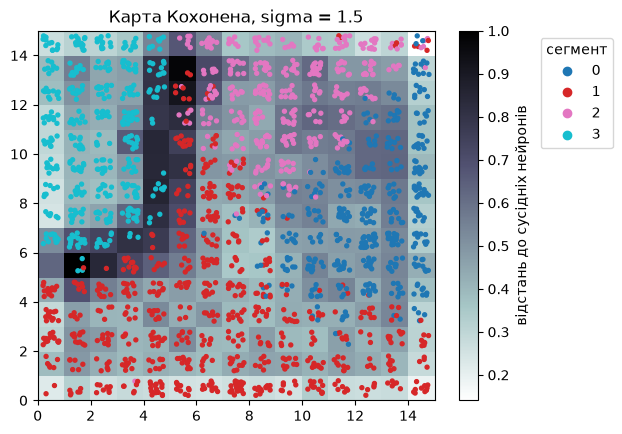

In [61]:
def train_som(sigma):
    som = MiniSom(15, 15, X.shape[1], sigma=sigma, learning_rate=0.5, random_seed=0)
    som.pca_weights_init(X)
    som.train(X, 20000, random_order=True)
    return som

som = train_som(1.5)
som_small = train_som(0.5)
print(f"топографічна помилка: sigma = 1.5 — {som.topographic_error(X):.3f}, sigma = 0.5 — {som_small.topographic_error(X):.3f}")

winners = np.array([som.winner(x) for x in X]) + 0.5
jitter = np.random.default_rng(0).uniform(-0.3, 0.3, size=winners.shape)
mesh = plt.pcolor(som.distance_map().T, cmap="bone_r")
plt.colorbar(mesh, label="відстань до сусідніх нейронів")
points = plt.scatter(*(winners + jitter).T, c=labels, s=8, cmap="tab10")
plt.legend(*points.legend_elements(), title="сегмент", loc="upper left", bbox_to_anchor=(1.25, 1))
plt.title("Карта Кохонена, sigma = 1.5")
plt.show()

Згідно отриманої мапи та топографічної помилки показують розбиття на 4 сегменти, один з яких явно відокремлений від інших, що збігається з попередніми результатами. Також видно, що інші сегменти дещо перетинаються один з одним, що також підтверджує попередні результати, отримані в пункті 6.

Перша мапа має меншу топографічну помилку, що означає краще збереження сусідства. Значення 0.156 каже, що у 15.6 % випадках два найближчі нейрони не є сусідами. Більший радіус призводить до кращого зберігання зв'язків між топологіями окремих абонентів.

## 9. Асоціативні правила

Правило «A → B» означає: у кого є A, у того часто є й B. Підтримка — частка абонентів, у яких є і A, і B. Достовірність — частка абонентів із B серед тих, у кого є A. Ліфт — у скільки разів достовірність більша за частку B у всій базі; ліфт 1 означає, що зв'язку немає.

Apriori відкидає набір, щойно його підтримка нижча за поріг, і вже не перевіряє ширших наборів із ним: ширший набір не може траплятися частіше за свою частину.

Код нижче вже будує таблицю «абонент × тип події» (подій `churn` у ній немає, замість них колонка `churned`) і знаходить правила з достовірністю від 0.3 для заданого порога підтримки.

1. Допишіть у `churn_rules` фільтр: лише правила, у яких наслідок рівно `churned` (`rules["consequents"] == frozenset({"churned"})`), відсортовані за ліфтом.
2. При підтримці 0.05 виведіть кількість цих правил і перші 5 із підтримкою, достовірністю й ліфтом.
3. При підтримці 0.10 виведіть, скільки правил лишилося.
4. Прочитайте найсильніше правило: у скільки разів частіше йдуть абоненти з цими подіями, ніж у середньому, і чому з вищим порогом правил менше, — це відповідь для питання 2 звіту.

In [73]:
no_churn = events[events["event_type"] != "churn"]
basket = pd.crosstab(no_churn["abonent_id"], no_churn["event_type"]) > 0  # True, якщо в абонента була хоч одна така подія
basket = basket.reindex(customers["abonent_id"], fill_value=False)  # абоненти без подій — рядок із False
basket["churned"] = customers["churned"].astype(bool).to_numpy()  # рядки йдуть у тому самому порядку, що в customers


def churn_rules(min_support):
    frequent = apriori(basket, min_support=min_support, use_colnames=True)  # набори подій, що трапляються не рідше за поріг
    rules = association_rules(frequent, num_itemsets=len(basket), metric="confidence", min_threshold=0.3)
    return rules[rules["consequents"] == frozenset({"churned"})].sort_values("lift", ascending=False)  # TODO: лише правила з наслідком рівно churned, від більшого ліфту до меншого


# TODO: кількість правил і перші 5 при підтримці 0.05; кількість правил при 0.10
pd.set_option(
    'display.max_colwidth', 100
)
support_gt_005 = churn_rules(0.05)

print("rules count while support greater then 0.05:", len(support_gt_005), support_gt_005["support"].sum())
display(support_gt_005[["antecedents","support", "confidence", "lift"]].head(5))

support_gt_01 = churn_rules(0.1)

print("rules count while support greater then 0.1:", len(support_gt_01), support_gt_01["support"].sum())
display(support_gt_01[["antecedents","support", "confidence", "lift"]])

rules count while support greater then 0.05: 25 2.3795


,antecedents,support,confidence,lift
154,"frozenset({complaint, contract_query, outage})",0.0635,0.585253,2.697021
250,"frozenset({outage, contract_query, tariff_change})",0.0565,0.573604,2.643337
174,"frozenset({complaint, contract_query, payment_delay})",0.0665,0.551867,2.543167
185,"frozenset({complaint, contract_query, tariff_change})",0.0745,0.551852,2.543096
218,"frozenset({complaint, outage, tariff_change})",0.0820,0.548495,2.527627


rules count while support greater then 0.1: 9 1.1929999999999998


,antecedents,support,confidence,lift
71,"frozenset({complaint, payment_delay})",0.1200,0.541761,2.496593
60,"frozenset({complaint, outage})",0.1130,0.531765,2.450529
76,"frozenset({complaint, tariff_change})",0.1295,0.526423,2.425911
93,"frozenset({tariff_change, payment_delay})",0.1020,0.513854,2.367990
8,frozenset({complaint}),0.1805,0.450687,2.076897
29,frozenset({tariff_change}),0.1570,0.447932,2.064201
17,frozenset({contract_query}),0.1140,0.442718,2.040177
27,frozenset({payment_delay}),0.1435,0.432229,1.991838
23,frozenset({outage}),0.1335,0.399103,1.839185


При мінімальній підтримці 0.05 отримуємо 25 правил, при мінімальній підтримці 0.1 - 9 правил. Найбільштй ліфт мають умови {complaint, contract_query, outage}: до цього правила відноситься 6.35% всіх абонентів, 58.52% яких змінило постачальника. Ці значення у 2.7 разів більші за середні по всій базі.

Збільшення підтримки означає, що до такого правила відноситься більше абонементів. Це в свою чергу призводить до менш специфічних наборів подій, тобто кількість подій в кожному наборі зменшується, вони стають більш загальними. У зв'язку і з цим кількість унікальних комбінацій також зменшується

## 10. Пастки (T-1, T-2, T-3)

Простий висновок із даних буває хибним. Що означає кожна пастка, сказано в таблиці в `README.md`. Перевірте кожну й виведіть числа, які порівнюються з порогом:

- **T-1:** кореляцію `voltage_dev_mean` і `loss_index_mean` по всій базі й окремо в кожному `district`;
- **T-2:** середню `seasonality` в абонентів із лічильниками `IND_1985`, у решти й відношення першої до другої;
- **T-3:** кореляцію `avg_price_uah_kwh` і `churned` серед 600 абонентів (30%) із найбільшим `annual_charge_uah` і серед решти.

Можуть допомогти `corr`, `groupby("district")` і `nlargest`.

In [84]:
# TODO: T-1

r_total = customers["voltage_dev_mean"].corr(customers["loss_index_mean"])

r_district = customers.groupby("district").apply(lambda g: g["voltage_dev_mean"].corr(g["loss_index_mean"]), include_groups=False)

t1 = abs(r_total) > 0.2 and (r_district.abs() < 0.1).all()

print("T1:", t1)
print("total corelation", r_total.round(3))
print("district corelation\n", r_district.round(3))

# TODO: T-2

meter_old = customers["meter_type"] == "IND_1985"

mean_old = customers.loc[meter_old, "seasonality"].mean()
mean_other = customers.loc[~meter_old, "seasonality"].mean()

x = mean_old / mean_other

t2 = x < 0.8 or x > 1.2

print("\nT2:", t2)
print("mean for old meters:", mean_old.round(3))
print("mean for other meters:", mean_other.round(3))
print("relation:", x)


# TODO: T-3

sorted_price = customers.sort_values("annual_charge_uah", ascending=False)

top30 = sorted_price.iloc[:600]
others = sorted_price.iloc[600:]

correlation_top30 = top30["avg_price_uah_kwh"].corr(top30["churned"])

correlation_other = others["avg_price_uah_kwh"].corr(others["churned"])

t3 = (correlation_top30 * correlation_other) < 0

print("\nT3:", t3)
print("correlation in top 600:", correlation_top30.round(3))
print("correlation in other:", correlation_other.round(3))

T1: True
total corelation 0.377
district corelation
 district
centre    0.011
north     0.021
south    -0.032
west      0.024
dtype: float64

T2: False
mean for old meters: 1.481
mean for other meters: 1.536
relation: 0.9642387024190979

T3: False
correlation in top 600: 0.275
correlation in other: 0.184


З цих перевірок видно, що в цьому варіанті присутня пастка Т1, тобто Прихований чинник: два показники пов'язані лише тому, що обидва залежать від третього

## 11. Самоперевірка й збереження

Якщо якась перевірка падає, поверніться до відповідного кроку.

In [85]:
x = np.asarray(X)
segments = pd.DataFrame({"abonent_id": customers["abonent_id"], "segment_id": labels})

assert x.shape == (2000, 5), "X має містити 2000 абонентів і 5 ознак із features"
assert np.allclose(x.mean(axis=0), 0) and np.allclose(x.std(axis=0), 1, atol=1e-3), "ознаки X не стандартизовано"
assert np.corrcoef(x[:, 0], np.log(customers["avg_daily_kwh"]))[0, 1] > 0.999, "перша колонка X — не логарифм avg_daily_kwh, або customers змінено чи пересортовано"
assert len(segments) == 2000 and segments["abonent_id"].is_unique, "має бути рядок на кожного з 2000 абонентів"
assert pd.api.types.is_integer_dtype(segments["segment_id"]), "segment_id мають бути цілі числа"
assert 3 <= segments["segment_id"].nunique() <= 6, "сегментів має бути від 3 до 6"

segments.to_csv("segments.csv", index=False)
print("усе гаразд:", segments["segment_id"].value_counts().sort_index().to_dict())

усе гаразд: {0: 438, 1: 744, 2: 373, 3: 445}
